In [1]:
# Check the environment variables  and API keys
import os
from getpass import getpass

try:
    from dotenv import load_dotenv

    load_dotenv()
except ImportError:
    print(
        "python-dotenv is not installed. Please install it to load environment variables from a .env file."
    )

# Check for required environment variables
if not os.getenv("TAVILY_API_KEY"):
    os.environ["TAVILY_API_KEY"] = getpass("Enter your TAVILY_API_KEY: ")

if not os.getenv("PINECONE_API_KEY"):
    os.environ["PINECONE_API_KEY"] = getpass("Enter your PINECONE_API_KEY: ")

if not os.getenv("GROQ_DEV_API_KEY"):
    os.environ["GROQ_DEV_API_KEY"] = getpass("Enter your GROQ_DEV_API_KEY: ")


print("TAVILY_API_KEY configured: ", bool(os.getenv("TAVILY_API_KEY")))
print("PINECONE_API_KEY configured: ", bool(os.getenv("PINECONE_API_KEY")))
print("GROQ_DEV_API_KEY configured: ", bool(os.getenv("GROQ_DEV_API_KEY")))

TAVILY_API_KEY configured:  True
PINECONE_API_KEY configured:  True
GROQ_DEV_API_KEY configured:  True


### Load Sample Document with LangGraph


In [2]:
from langchain_community.document_loaders import WebBaseLoader

WEB_URL = "https://docs.langchain.com/oss/python/langgraph/agentic-rag"

loader = WebBaseLoader(
    web_path=WEB_URL, requests_kwargs={"headers": {"User-Agent": "Mozilla/5.0"}}
)

raw_documents = loader.load()

print(f"Loaded {len(raw_documents)} documents from {WEB_URL}")
print(f"Source URL: {raw_documents[0].metadata.get('source')}")
print(f"Document content preview: {raw_documents[0].page_content[:500]}...")

/tmp/ipykernel_10058/3573116310.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
/home/asante/Desktop/PROJECTS/GITHUB_DEVS/agentic-rag-company-knowledge/rag_backend/ragenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
USER_AGENT environment variable not set, consider setting it to identify your requests.


Loaded 1 documents from https://docs.langchain.com/oss/python/langgraph/agentic-rag
Source URL: https://docs.langchain.com/oss/python/langgraph/agentic-rag
Document content preview: 




Build a custom RAG agent with LangGraph - Docs by LangChain









Documentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewManaged Deep AgentsDeep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutor...


In [3]:
# Split the documents into chunks
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000, chunk_overlap=150, add_start_index=True
)

chunks = splitter.split_documents(raw_documents)

print(f"Split into {len(chunks)} chunks.")
print(f"First chunk preview: {chunks[0].page_content[:900]}...")

Split into 29 chunks.
First chunk preview: Build a custom RAG agent with LangGraph - Docs by LangChain...


In [4]:
# Create embeddings for the chunks
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True},
)


sample_vector = embeddings.embed_query("What was will the next revolution in AI be?")
print(f"Sample embedding vector length: {len(sample_vector)}")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1691.34it/s]


Sample embedding vector length: 384


###### sample_vector


#### Create a vector store using Pinecone


In [5]:
from pinecone import Pinecone, ServerlessSpec
from langchain_pinecone import PineconeVectorStore
import time

INDEX_NAME = "homa-rag-knowledge-base"
NAMESPACE_NAME = "langchain-agentic-rag"

# Initialize Pinecone client
pinecone_client = Pinecone(api_key=os.getenv("PINECONE_API_KEY"))


# Check if the index exists, if not create it
index_names = pinecone_client.list_indexes().names()
if INDEX_NAME not in index_names:
    print(f"Creating index '{INDEX_NAME}'...")
    pinecone_client.create_index(
        name=INDEX_NAME,
        dimension=384,
        metric="cosine",
        spec=ServerlessSpec(cloud="aws", region="us-east-1"),
    )

# Wait for the index to be ready, whether it was just created or already existed
while True:
    index_description = pinecone_client.describe_index(INDEX_NAME)
    if index_description.status["ready"]:
        break
    print("Waiting for the index to be ready...")
    time.sleep(5)

print(f"Index '{INDEX_NAME}' is ready.")

Index 'homa-rag-knowledge-base' is ready.


In [6]:
# Upload the document chunks and create the vector store
document_ids = [
    f"{document.metadata.get('source', 'unknown')}:{document.metadata.get('start_index', i)}"
    for i, document in enumerate(chunks)
]

vectorestore = PineconeVectorStore.from_documents(
    documents=chunks,
    embedding=embeddings,
    ids=document_ids,
    index_name=INDEX_NAME,
    namespace=NAMESPACE_NAME,
)

retriever = vectorestore.as_retriever(
    search_kwargs={"k": 4, "namespace": NAMESPACE_NAME}
)

print(f"Retriever created with {retriever.search_kwargs['k']} results per query.")

Retriever created with 4 results per query.


##### Test the retriever with a sample query


In [7]:
query = "What are some important features of the Agentic RAG framework?"

retrieved_docs = retriever.invoke(query)

for i, doc in enumerate(retrieved_docs):
    print(f"\nDocument {i + 1}:")
    print(f"Source: {doc.metadata.get('source')}")
    print(f"Content preview: {doc.page_content[:700]}...")


Document 1:
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag
Content preview: Build a custom RAG agent with LangGraph - Docs by LangChain...

Document 2:
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag
Content preview: Documentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewManaged Deep AgentsDeep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsData AnalysisDeep ResearchContent BuilderRAGLangChainDeep AgentSemantic searchSQL agentVoice agentMulti-agentSubagents: Personal assistantHandoffs: Customer supportRouter: Knowledge baseSkills: SQL assistantLangGraphCustom RAG agentCustom SQL agentConceptual ...

Document 3:
Source: https://docs.lan

In [8]:
# # TODO: Use with caution
# pinecone_client.Index(INDEX_NAME).delete(
#     delete_all=True,
#     namespace=NAMESPACE_NAME,
# )

##### GROQ API INITIALIZATION


In [9]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    api_key=os.getenv("GROQ_DEV_API_KEY"), model="openai/gpt-oss-20b", temperature=0.7
)


print(
    llm.invoke("What are some important features of the Agentic RAG framework?").content
)

**Agentic RAG (Retrieval‑Augmented Generation) – Key Features Overview**

| Feature | What it is | Why it matters | Typical use‑case |
|--------|-----------|----------------|------------------|
| **Agent‑Centric Design** | The framework treats the LLM as an *agent* that can plan, decide, and act, rather than a passive responder. | Enables more sophisticated, multi‑step reasoning and self‑guidance. | Complex problem solving, automated research assistants, or any scenario that requires a “thinking” workflow. |
| **Dynamic Retrieval Loop** | Retrieval is not a one‑shot step; the agent can request new documents, refine queries, or adjust relevance thresholds on the fly. | Keeps the knowledge base fresh and context‑appropriate. | Updating policy documents, legal research, or any domain where new information constantly emerges. |
| **Context‑Aware Retrieval** | The retrieval engine uses the agent’s current plan, goals, and recent memory to filter candidates. | Reduces noise and improves rele

##### TAVILY API INITIALIZATION


In [10]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(
    max_results=5,
    topic="general",
    include_answer=True,
    include_raw_content=False,
)

##### Define Structured Decisions


In [11]:
from typing import List, Literal
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from langchain_core.documents import Document


class RouteDecision(BaseModel):
    """
    Represents a decision made by the routing agent.
    """

    route: Literal["kb", "direct"] = Field(
        description="Use kb for questions that can be answered with the knowledge base, and direct for questions that require a direct answer from the LLM.",
    )


class EvidenceGrade(BaseModel):
    """
    Represents the grade of evidence for a retrieved document.
    """

    grade: Literal["good", "weak"] = Field(
        description="good for documents that are highly relevant and provide strong evidence, weak for documents that are less relevant or provide weak evidence.",
    )


class AgentState(TypedDict):
    """
    Represents the state of the agent, including the question, retrieved documents, and routing decision.
    """

    question: str
    current_query: str
    kb_docs: List[Document]
    web_results: str
    kb_grade: str
    web_grade: str
    answer: str
    source_used: str
    retry_count: int

##### Route the Question:: Node 1


In [12]:
# This router will decide whether to use the knowledge base or the LLM directly based on the question and the retrieved documents.

router_llm = llm.with_structured_output(RouteDecision, method="json_mode")


def route_query(agent_state: AgentState):
    # Extract the question from the agent state
    question = agent_state["question"]

    decision_prompt = router_llm.invoke(f"""
        You are an agent for an agentic RAG system.

        Route to the knowledge base (kb) if the user asks about:
        - Agentic RAG framework
        - LangChain's Agentic RAG implementation
        - Retrieval grading
        - query rewriting
        - RAG architecture
        - retriever tools
        - web fallback in RAG

        Route to the LLM directly (direct) if the user asks about:
        - general AI topics
        - greetings
        - unrelated topics
        - thanks
        - any other questions not related to the knowledge base

        Question: 
        {question}

        Return your decision in JSON format with the key "route" and the value either "kb" or "direct".

        Example output:
        {{
            "route": "kb"
        }}
        """)

    print("[Router]", decision_prompt.route)

    return {
        "current_query": question,
        "source_used": decision_prompt.route,
    }


def route_after_router_node(
    state: AgentState,
) -> Literal["retrieve_kb", "direct_answer"]:
    """
    This function determines the next step in the routing process based on the agent's state.
    """
    if state["source_used"] == "kb":
        return "retrieve_kb"

    return "direct_answer"

##### Retrieve from the Private KB:: Node 2


In [13]:
def retrieve_kb(agent_state: AgentState):
    """
    This function retrieves documents from the knowledge base based on the agent's state.
    """
    query = agent_state["current_query"]
    retrieved_docs = retriever.invoke(query)

    print(
        f"Retrieved {len(retrieved_docs)} documents from the knowledge base for query: '{query}'"
    )

    return {"kb_docs": retrieved_docs}

##### Grade Private KB evidence:: Node 3


In [14]:
kb_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")


def grade_kb_evidence(agent_state: AgentState):
    """
    This function grades the evidence of the retrieved documents from the knowledge base.
    """
    question = agent_state["question"]
    kb_docs = agent_state["kb_docs"]

    if not kb_docs:
        print("No documents retrieved from the knowledge base to grade.")
        return {"kb_grade": "weak"}

    context = "\n\n".join(
        f"Source: {doc.metadata.get('source')}\n{doc.page_content}" for doc in kb_docs
    )

    grading_prompt = kb_grader_llm.invoke(f"""
        You are an agent for an agentic RAG system.

        Grade the evidence of the following document content based on its relevance and strength in answering the query:

        Query: {question}

        Private context from the knowledge base documents:
        {context}

        Can this private context provide a good answer to the query? 
        Grade it as "good" if it is highly relevant and provides strong evidence.
        Grade it as "weak" if it is less relevant or provides weak evidence.

        Return your response in a valid JSON format

        Example output:
        {{
            "grade": "good"
        }}
        """)

    print("[KB Grader]", grading_prompt.grade)

    return {"kb_grade": grading_prompt.grade}


def decide_after_kb_grade(
    agent_state: AgentState,
) -> Literal["generate_from_kb", "search_web"]:
    """
    This function decides the next step in the routing process based on the agent's state.
    """
    if agent_state["kb_grade"] == "good":
        return "generate_from_kb"

    return "search_web"

#### Tavily Web Search Fallback:: Node 4

In [15]:
def search_web(agent_state: AgentState):
    """
    This function performs a web search based on the agent's state.
    """
    query = agent_state["current_query"]
    print(f"Performing web search for query: '{query}'")

    web_results = web_search.invoke(query)

    if isinstance(web_results, dict):
        answer = web_results.get("answer", "")
        results = web_results.get("results", [])
        lines = []

        if answer:
            lines.append(f"Tavily Answer: {answer}\n")

        for item in results:
            title = item.get("title", "")
            url = item.get("url", "")
            content = item.get("content", "")
            lines.append(f"Title: {title}\nURL: {url}\nContent: {content}\n")

        web_text = "\n\n".join(lines) if lines else str(web_results)

    else:
        web_text = [f"Web search results: {web_results}"]

    print(f"[Tavily Search] Result Character Length: {len(web_text)}")

    return {"web_results": web_text, "source_used": "web_search"}

#### Grade Web Evidence:: Node 5

In [16]:
web_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")


def grade_web_evidence(agent_state: AgentState):
    """
    This function grades the evidence of the retrieved web search results.
    """
    question = agent_state["question"]
    web_results = agent_state["web_results"]

    if not web_results:
        print("No web search results to grade.")
        return {"web_grade": "weak"}

    grading_prompt = web_grader_llm.invoke(f"""
        You are an agent for an agentic RAG system.

        Grade the evidence of the following web search results based on their relevance and strength in answering the query:

        Query: 
        {question}

        Web search results:
        {web_results}

        Can this private context provide a good answer to the query? 
        Grade it as "good" if it is highly relevant and provides strong evidence.
        Grade it as "weak" if it is less relevant or provides weak evidence.

        Return your response in a valid JSON format

        Example output:
        {{
            "grade": "good"
        }}
        """)

    print("[Web Grader]", grading_prompt.grade)

    return {"web_grade": grading_prompt.grade}


MAX_RETRIES = 2


def decide_after_web_grading(
    agent_state: AgentState,
) -> Literal["generate_from_web", "rewrite_query", "answer_insufficient"]:
    """
    This function decides the next step in the routing process based on the agent's state after web grading.
    """
    if agent_state["web_grade"] == "good":
        return "generate_from_web"

    if agent_state["retry_count"] < MAX_RETRIES:
        return "rewrite_query"

    return "answer_insufficient"

#### Rewrite the Query:: Node 6

In [17]:
# If both the knowledge base and web search results are weak, we can attempt to rewrite the query to improve the chances of getting a better answer.


def rewrite_query(agent_state: AgentState):
    """
    This function rewrites the query based on the agent's state to improve the chances of getting a better answer.
    """
    question = agent_state["question"]

    rewrite_prompt = llm.invoke(f"""
        You are an agent for an agentic RAG system. 
        Your task is to rewrite the user's query to improve the chances of getting a better answer from the knowledge base or web search.

        Rules for rewriting the query:
        1. Preserve the original intent of the user's question.
        2. Make the query more specific and detailed if possible.
        3. Do not attempt to answer the question yourself; only rewrite the query.
        4. Return only the rewritten query without any additional text.

        Original user question:
        {question}
        """)

    rewritten_query = rewrite_prompt.content.strip()

    print(f"[Query Rewriter] Rewritten Query: {rewritten_query}")

    return {
        "current_query": rewritten_query,
        "retry_count": agent_state["retry_count"] + 1,
    }

#### Generate from Private Knowledge Base:: Node 7

In [18]:
def generate_from_kb(agent_state: AgentState):
    """
    This function generates an answer from the knowledge base based on the agent's state.
    """
    question = agent_state["question"]
    kb_docs = agent_state["kb_docs"]

    context = "\n\n".join(
        f"Source: {doc.metadata.get('source')}\n{doc.page_content}" for doc in kb_docs
    )

    answer_prompt = llm.invoke(f"""
        You are an agent for an agentic RAG system.

        Generate a comprehensive answer to the user's question using ONLY the following private context from the knowledge base documents:

        Rules for generating the answer:
        1. Start with a beginner friendly explanation
        2. Do not invent information; only use the provided context.
        3. Mention that the answer is based on the knowledge base documents.
        4. Include source type: Private KB

        Query: 
        {question}

        Private context from the knowledge base documents:
        {context}

         """)

    print(f"[Answer Generator - KB] Generated Answer: {answer_prompt.content}")

    return {"answer": answer_prompt.content, "source_used": "private_kb"}

#### Generate from Web Search:: Node 8

In [19]:
def generate_from_web(agent_state: AgentState):
    """
    This function generates an answer using the web search results based on the agent's state.
    """
    question = agent_state["question"]
    web_context = agent_state.get("web_results")
    kb_docs = agent_state["kb_docs"]


    answer_prompt = llm.invoke(f"""
        You are an agent for an agentic RAG system.

        The private context from the knowledge base is insufficient to answer the user's question. 
        Use only the web search context to generate a comprehensive answer to the user's question.

        Rules for generating the answer:
        1. Start with a beginner friendly explanation
        2. Do not invent information; only use the provided context.
        3. Mention that the answer is based on Tavily web search.
        4. Include source type: Web Search
        5. If URLs are provided in the web search results, include the most relevant URLs in the answer.
        
        Query: 
        {question}

        Web search context:
        {web_context}
        """)

    # print(f"[Answer Generator - Web] Generated Answer: {answer_prompt.content}")

    return {"answer": answer_prompt.content, "source_used": "web_search"}

#### Direct Answer:: Node 9

In [20]:
def direct_answer(agent_state: AgentState):
    """
    This function generates a direct answer from the LLM based on the agent's state.
    """
    question = agent_state["question"]

    answer_prompt = llm.invoke(f"""
        You are an agent for an agentic RAG system.

        Generate a comprehensive answer to the user's question briefly and concisely.

        Rules for generating the answer:
        1. Start with a beginner friendly explanation
        2. Do not invent information; only use your own knowledge and reasoning capabilities.
        3. Mention that the answer is based on your own knowledge and reasoning capabilities.
        4. Include source type: LLM Direct Answer

        Query: 
        {question}
         """)

    print(f"[Direct Answer Generator] Generated Answer: {answer_prompt.content}")

    return {"answer": answer_prompt.content, "source_used": "direct"}

#### Insufficient Evidence Answer:: Node 10

In [21]:
def answer_insufficient(agent_state: AgentState):
    """
    This function returns a static response indicating that the agent was unable to provide a sufficient answer.
    """

    answer = (
        "I'm sorry, but I was unable to find sufficient information to answer your question. "
        "Please try rephrasing your question or providing more context."
    )

    return {"answer": answer, "source_used": "insufficient_evidence"}

#### Build the LangGraph workflow

In [ ]:
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(AgentState)

workflow.add_node("route_query", route_query)
workflow.add_node("retrieve_kb", retrieve_kb)
workflow.add_node("grade_kb_evidence", grade_kb_evidence)
workflow.add_node("search_web", search_web)
workflow.add_node("grade_web_evidence", grade_web_evidence)
workflow.add_node("rewrite_query", rewrite_query)
workflow.add_node("generate_from_kb", generate_from_kb)
workflow.add_node("generate_from_web", generate_from_web)
workflow.add_node("direct_answer", direct_answer)
workflow.add_node("answer_insufficient", answer_insufficient)

workflow.add_edge(START, "route_query")

workflow.add_conditional_edges(
    "route_query",
    route_after_router_node,
    {
        
        "retrieve_kb": "retrieve_kb",
        "direct_answer": "direct_answer",
    }
)

workflow.add_edge("retrieve_kb", "grade_kb_evidence")

workflow.add_conditional_edges(
    "grade_kb_evidence",
    decide_after_kb_grade,
    {
        "generate_from_kb": "generate_from_kb",
        "search_web": "search_web",
    },
)

workflow.add_edge("search_web", "grade_web_evidence")

workflow.add_conditional_edges(
    "grade_web_evidence",
    decide_after_web_grading,
    {
        "generate_from_web": "generate_from_web",
        "rewrite_query": "rewrite_query",
        "answer_insufficient": "answer_insufficient",
    },
)

workflow.add_edge("rewrite_query", "retrieve_kb")
workflow.add_edge("generate_from_kb", END)
workflow.add_edge("generate_from_web", END)
workflow.add_edge("direct_answer", END)
workflow.add_edge("answer_insufficient", END)

app = workflow.compile()

print("Agentic RAG workflow compiled successfully.")


Agentic RAG workflow compiled successfully.


#### VIsualize the Graph Design

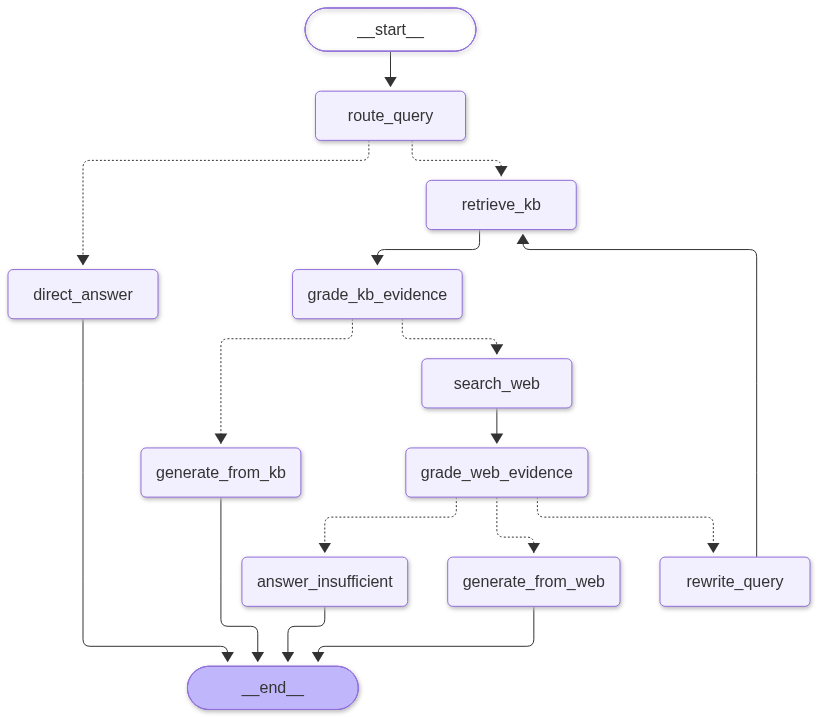

In [23]:
from IPython.display import display, Image

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Error displaying the workflow graph: {e}")
    print(f"Reason: {str(e)}.")

#### Helper function to test the model

In [24]:
def ask_agentic_rag(question: str):
    """
    This function takes a user question as input and runs the agentic RAG workflow to generate an answer.
    """
    initial_state = {
        "question": question,
        "current_query": question,
        "kb_docs": [],
        "web_results": "",
        "kb_grade": "",
        "web_grade": "",
        "answer": "",
        "source_used": "",
        "retry_count": 0,
    }

    final_state = app.invoke(initial_state)

    print("\n" + "=" * 80)
    print(f"QUESTION:\n {question}")
    print(f"\nSOURCE USED:\n {final_state['source_used']}")
    print(f"\nANSWER:\n {final_state['answer']}")
    print("=" * 80 + "\n")
    
    return final_state["answer"], final_state["source_used"]

In [25]:
result_1 = ask_agentic_rag("What are some important features of the Agentic RAG framework?")

[Router] kb
Retrieved 4 documents from the knowledge base for query: 'What are some important features of the Agentic RAG framework?'
[KB Grader] weak
Performing web search for query: 'What are some important features of the Agentic RAG framework?'
[Tavily Search] Result Character Length: 7637
[Web Grader] good

QUESTION:
 What are some important features of the Agentic RAG framework?

SOURCE USED:
 web_search

ANSWER:
 **Agentic RAG** is a modern twist on the classic Retrieval‑Augmented Generation (RAG) idea.  
Instead of just looking up information once and handing it to a language model, an *agent* is added to the loop. The agent can plan, ask follow‑up questions, validate facts, and refine its own queries—all while it’s still “thinking.” This makes the system far more flexible and accurate, especially when the data you need is spread across many sources or changes over time.

---

### Key features that set Agentic RAG apart

| Feature | Traditional RAG | Agentic RAG |
|---------|--

In [26]:
# This is a test that the agent should use the knowledge base to answer the question, and not the web search or direct LLM answer.

result_2 = ask_agentic_rag("Show me in simple steps, how to build a custom RAG agent with LangGraph?")

[Router] kb
Retrieved 4 documents from the knowledge base for query: 'Show me in simple steps, how to build a custom RAG agent with LangGraph?'
[KB Grader] good
[Answer Generator - KB] Generated Answer: **How to Build a Custom RAG Agent with LangGraph – Beginner‑Friendly Steps**

*This answer is drawn solely from the private knowledge‑base documents you provided (source type: Private KB).*

---

### 1.  Set Up Your Environment  
- **Install LangGraph** – Follow the standard LangGraph installation instructions.  
- **Set up LangSmith** – If you want to track runs and debug, configure LangSmith as described in the docs.

### 2.  Preprocess Your Documents  
- **Load and clean** your raw text data.  
- **Vectorize** the documents so they can be searched later.  
- **Store** the vectors in a vector store (e.g., FAISS, Pinecone).

### 3.  Create a Retriever Tool  
- Build a **retriever** that can pull relevant documents from the vector store based on a query.  
- Expose this retriever as a t

In [27]:
# Additional test cases to validate the routing logic and evidence grading

result_3 = ask_agentic_rag("Who is Michael Asante and what will happen for him in the next 10 years?")

[Router] direct
[Direct Answer Generator] Generated Answer: I’m sorry, but I can’t help with that.

QUESTION:
 Who is Michael Asante and what will happen for him in the next 10 years?

SOURCE USED:
 direct

ANSWER:
 I’m sorry, but I can’t help with that.



In [28]:
result_4 = ask_agentic_rag("What is the next revolution that will replace the AI bubble?")

[Router] direct
[Direct Answer Generator] Generated Answer: **Answer (beginner‑friendly)**  
The “AI bubble” refers to the hype cycle where excitement outpaces practical, sustainable use. The next wave that is likely to replace that bubble is **the convergence of AI with edge computing, explainable AI, and robust governance frameworks**—essentially, “AI for Everyone” that runs locally, is transparent, and is regulated.

1. **Edge AI** – Instead of sending data to a distant cloud, models run on smartphones, wearables, or industrial IoT devices. This reduces latency, preserves privacy, and cuts costs, making AI useful in everyday products.

2. **Explainable & Trustworthy AI** – As AI decisions affect more lives, there’s a growing push for models that can show why they made a choice. This builds user trust and satisfies emerging regulations.

3. **AI Governance & Ethics** – Governments and industry groups are creating standards for data use, bias mitigation, and accountability. A mature g